In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    confusion_matrix, classification_report, precision_score,
    recall_score, f1_score, accuracy_score
)
import joblib

In [2]:
train = pd.read_csv("../data/train.csv", parse_dates=["date"])
stores = pd.read_csv("../data/stores.csv")
oil = pd.read_csv("../data/oil.csv", parse_dates=["date"])
holidays = pd.read_csv("../data/holidays_events.csv", parse_dates=["date"])
 
print(train.shape)
train.head()

(3000888, 6)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [3]:
daily_sales = train.groupby("date")["sales"].sum().reset_index()
daily_sales.columns = ["date", "total_sales"]

In [4]:
daily_sales = daily_sales.merge(oil, on="date", how="left")
daily_sales.rename(columns={"dcoilwtico": "oil_price"}, inplace=True)
daily_sales["oil_price"] = daily_sales["oil_price"].ffill().bfill()

In [5]:
holidays_simple = holidays[holidays["transferred"] == False][["date", "type"]].drop_duplicates(subset="date")
daily_sales = daily_sales.merge(holidays_simple, on="date", how="left")
daily_sales["is_holiday"] = daily_sales["type"].notna().astype(int)
daily_sales.drop(columns=["type"], inplace=True)
daily_sales = daily_sales.sort_values("date").reset_index(drop=True)

In [6]:
holiday_dates = daily_sales.loc[daily_sales["is_holiday"] == 1, "date"].sort_values().unique()
holiday_dates = pd.to_datetime(holiday_dates)
 
def days_to_next_holiday(date, holiday_list):
    future_holidays = holiday_list[holiday_list >= date]
    if len(future_holidays) == 0:
        return 999
    return (future_holidays.min() - date).days
 
def days_since_last_holiday(date, holiday_list):
    past_holidays = holiday_list[holiday_list <= date]
    if len(past_holidays) == 0:
        return 999
    return (date - past_holidays.max()).days
 
daily_sales["days_to_next_holiday"] = daily_sales["date"].apply(
    lambda d: days_to_next_holiday(d, holiday_dates))
daily_sales["days_since_last_holiday"] = daily_sales["date"].apply(
    lambda d: days_since_last_holiday(d, holiday_dates))
 
daily_sales["is_pre_holiday"] = (
    (daily_sales["days_to_next_holiday"] >= 1) &
    (daily_sales["days_to_next_holiday"] <= 3)
).astype(int)
 
daily_sales["is_post_holiday"] = (
    (daily_sales["days_since_last_holiday"] >= 1) &
    (daily_sales["days_since_last_holiday"] <= 2)
).astype(int)

In [7]:
daily_sales["year"] = daily_sales["date"].dt.year
daily_sales["month"] = daily_sales["date"].dt.month
daily_sales["day"] = daily_sales["date"].dt.day
daily_sales["day_of_week"] = daily_sales["date"].dt.dayofweek
daily_sales["is_weekend"] = daily_sales["day_of_week"].isin([5, 6]).astype(int)

In [8]:
daily_sales["lag_1"] = daily_sales["total_sales"].shift(1)
daily_sales["lag_7"] = daily_sales["total_sales"].shift(7)
daily_sales["rolling_mean_7"] = daily_sales["total_sales"].shift(1).rolling(7).mean()
daily_sales["rolling_mean_30"] = daily_sales["total_sales"].shift(1).rolling(30).mean()
 
daily_sales = daily_sales.dropna().reset_index(drop=True)
daily_sales.head()

,date,total_sales,oil_price,is_holiday,days_to_next_holiday,days_since_last_holiday,is_pre_holiday,is_post_holiday,year,month,day,day_of_week,is_weekend,lag_1,lag_7,rolling_mean_7,rolling_mean_30
0,2013-01-31,271254.217996,97.65,0,11,19,0,0,2013,1,31,3,0,281061.127052,247245.690995,316070.048174,335212.350630
1,2013-02-01,369402.055266,97.46,0,10,20,0,0,2013,2,1,4,0,271254.217996,290022.771930,319499.837745,344170.437264
2,2013-02-02,518887.462705,97.46,0,9,21,0,0,2013,2,2,5,1,369402.055266,413799.767975,330839.735365,339947.425174
3,2013-02-03,486336.820180,97.46,0,8,22,0,0,2013,2,3,6,1,518887.462705,430411.991233,345852.263183,345194.966227
4,2013-02-04,344308.715017,96.21,0,7,23,0,0,2013,2,4,0,0,486336.820180,285460.169953,353841.524461,349590.870997


In [9]:
features = ["year", "month", "day", "day_of_week", "is_weekend",
            "oil_price", "is_holiday", "is_pre_holiday", "is_post_holiday",
            "days_to_next_holiday", "lag_1", "lag_7",
            "rolling_mean_7", "rolling_mean_30"]
target = "total_sales"
 
split_index = int(len(daily_sales) * 0.8)
train_data = daily_sales.iloc[:split_index]
test_data = daily_sales.iloc[split_index:]
 
X_train, y_train = train_data[features], train_data[target]
X_test, y_test = test_data[features], test_data[target]

In [10]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=200, learning_rate=0.05, random_state=42)
}
 
results = {}
predictions = {}
 
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    predictions[name] = preds
 
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
 
    results[name] = {"RMSE": rmse, "MAE": mae, "R2": r2}
    print(f"{name} -> RMSE: {rmse:.2f}, MAE: {mae:.2f}, R2: {r2:.4f}")
 
results_df = pd.DataFrame(results).T
print("\n", results_df)
 
best_model_name = results_df["R2"].idxmax()
best_model = models[best_model_name]
y_pred = predictions[best_model_name]
print(f"\nBest model: {best_model_name}")

Linear Regression -> RMSE: 136427.05, MAE: 86450.81, R2: 0.4581
Random Forest -> RMSE: 130751.72, MAE: 84644.00, R2: 0.5022
XGBoost -> RMSE: 120385.92, MAE: 82067.63, R2: 0.5780

                             RMSE           MAE        R2
Linear Regression  136427.051752  86450.809150  0.458082
Random Forest      130751.721652  84643.998027  0.502232
XGBoost            120385.916914  82067.627120  0.578028

Best model: XGBoost


In [11]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
 
print("===== REGRESSION METRICS =====")
print(f"RMSE: {rmse:.2f}")
print(f"MAE:  {mae:.2f}")
print(f"R2 Score: {r2:.4f}")
print(f"MAPE: {mape:.2f}%")
 

===== REGRESSION METRICS =====
RMSE: 120385.92
MAE:  82067.63
R2 Score: 0.5780
MAPE: 27.25%


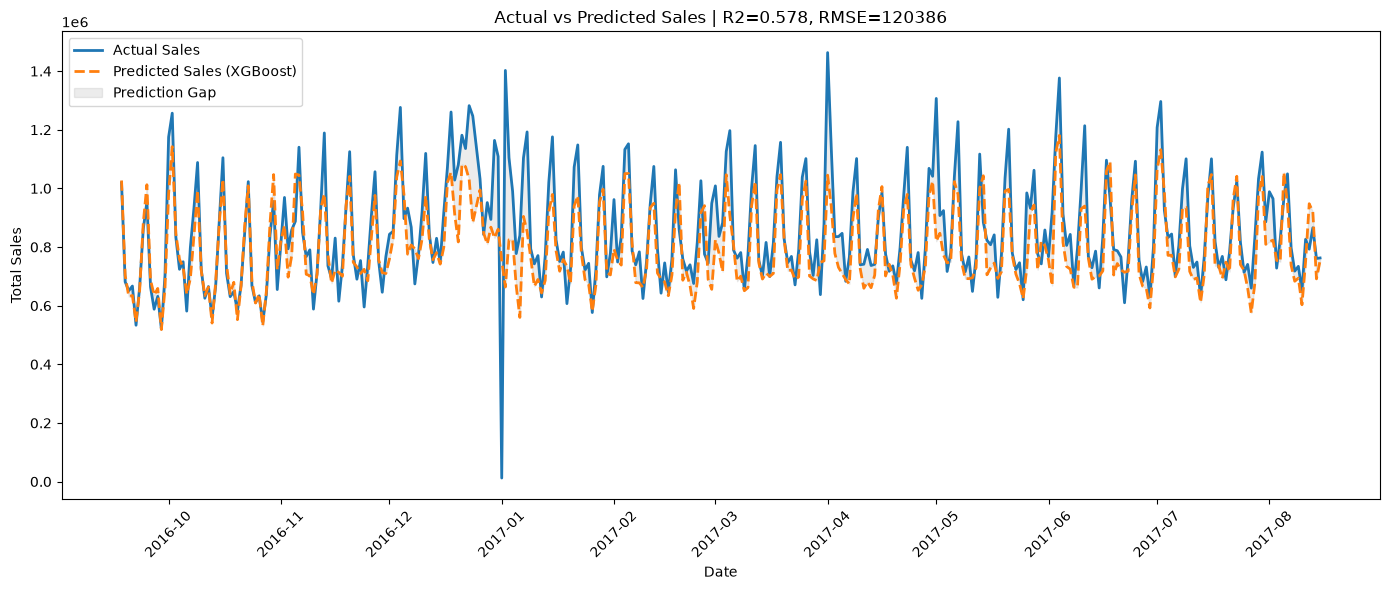

In [12]:
plt.figure(figsize=(14, 6))
plt.plot(test_data["date"].values, y_test.values,
         label="Actual Sales", color="#1f77b4", linewidth=2)
plt.plot(test_data["date"].values, y_pred,
         label=f"Predicted Sales ({best_model_name})",
         color="#ff7f0e", linewidth=2, linestyle="--")
plt.fill_between(test_data["date"].values, y_test.values, y_pred,
                  color="gray", alpha=0.15, label="Prediction Gap")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.title(f"Actual vs Predicted Sales | R2={r2:.3f}, RMSE={rmse:.0f}")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("sales_forecast_actual_vs_predicted.png", dpi=150)
plt.show()

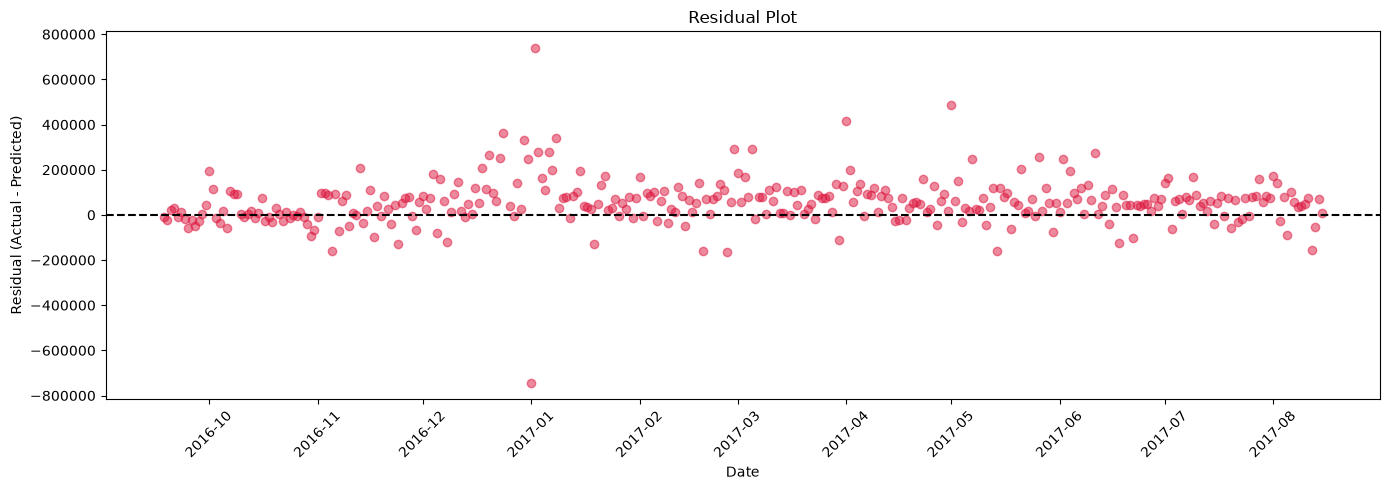

In [13]:
residuals = y_test.values - y_pred
 
plt.figure(figsize=(14, 5))
plt.scatter(test_data["date"].values, residuals, alpha=0.5, color="crimson")
plt.axhline(y=0, color="black", linestyle="--")
plt.xlabel("Date")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("residual_plot.png", dpi=150)
plt.show()

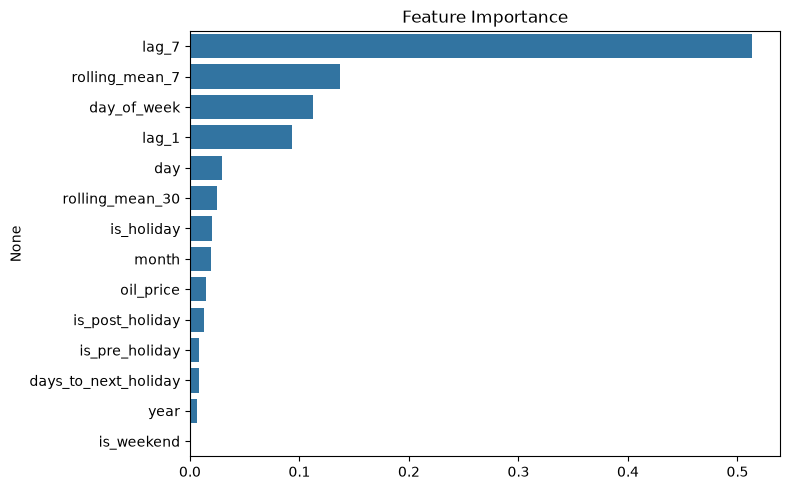

In [14]:
if best_model_name in ["Random Forest", "XGBoost"]:
    importance = pd.Series(best_model.feature_importances_, index=features).sort_values(ascending=False)
    plt.figure(figsize=(8, 5))
    sns.barplot(x=importance.values, y=importance.index)
    plt.title("Feature Importance")
    plt.tight_layout()
    plt.savefig("feature_importance.png", dpi=150)
    plt.show()

===== CLASSIFICATION-STYLE METRICS (Low/Medium/High buckets) =====
Accuracy:  72.51%
Precision: 72.51%
Recall:    72.51%
F1 Score:  72.51%


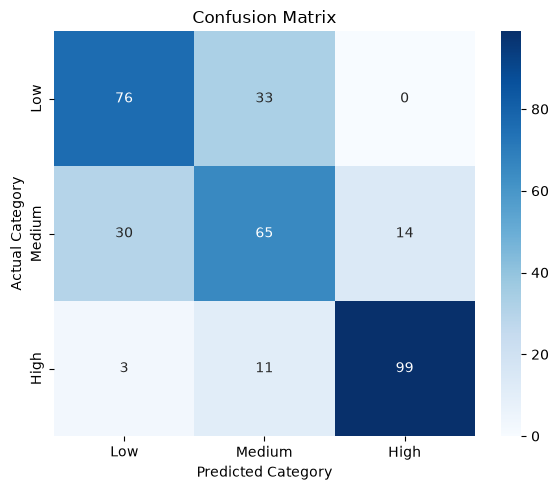

In [15]:
def categorize_sales(series):
    q1 = series.quantile(0.33)
    q2 = series.quantile(0.66)
    return pd.cut(series, bins=[-np.inf, q1, q2, np.inf],
                   labels=["Low", "Medium", "High"])
 
y_test_cat = categorize_sales(pd.Series(y_test.values))
y_pred_cat = categorize_sales(pd.Series(y_pred))
 
print("===== CLASSIFICATION-STYLE METRICS (Low/Medium/High buckets) =====")
print(f"Accuracy:  {accuracy_score(y_test_cat, y_pred_cat) * 100:.2f}%")
print(f"Precision: {precision_score(y_test_cat, y_pred_cat, average='weighted') * 100:.2f}%")
print(f"Recall:    {recall_score(y_test_cat, y_pred_cat, average='weighted') * 100:.2f}%")
print(f"F1 Score:  {f1_score(y_test_cat, y_pred_cat, average='weighted') * 100:.2f}%")
 
cm = confusion_matrix(y_test_cat, y_pred_cat, labels=["Low", "Medium", "High"])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Low", "Medium", "High"],
            yticklabels=["Low", "Medium", "High"])
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [16]:
os.makedirs("../models", exist_ok=True)
joblib.dump(best_model, "../models/sales_model.pkl")
print("Model saved to ../models/sales_model.pkl")

Model saved to ../models/sales_model.pkl
